# Plant Leaf Disease Classification with CNN (PlantVillage)
Deep Learning course project: custom CNN vs. MobileNetV2 transfer learning.
**Runtime > Change runtime type > GPU (T4)** before running.

In [ ]:
!pip -q install kagglehub
import kagglehub
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Path to dataset files: /kaggle/input/plantvillage-dataset


In [ ]:
import os, random, numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Find the 'color' folder automatically (folder layout may differ between versions)
DATA_DIR = None
for root, dirs, files in os.walk(path):
    if os.path.basename(root).lower() == "color" and len(dirs) > 10:
        DATA_DIR = root; break
print("Using:", DATA_DIR)

total = sum(len(f) for _, _, f in os.walk(DATA_DIR))
print("Total images:", total)

Using: /kaggle/input/plantvillage-dataset/plantvillage dataset/color
Total images: 54305


## 1. Data loading (70% train / 15% val / 15% test)

In [ ]:
IMG = (160, 160)   # smaller than 224 -> faster on Colab; raise to (224,224) if you like
BATCH = 32

full = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=IMG, batch_size=BATCH, shuffle=True, seed=SEED)
class_names = full.class_names
num_classes = len(class_names)
print(num_classes, "classes")

n = tf.data.experimental.cardinality(full).numpy()
n_train, n_val = int(n*0.70), int(n*0.15)
train_ds = full.take(n_train)
val_ds   = full.skip(n_train).take(n_val)
test_ds  = full.skip(n_train + n_val)

# reshuffle_each_iteration=False above is not set on 'full', so freeze splits by caching order:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 54305 files belonging to 38 classes.
38 classes


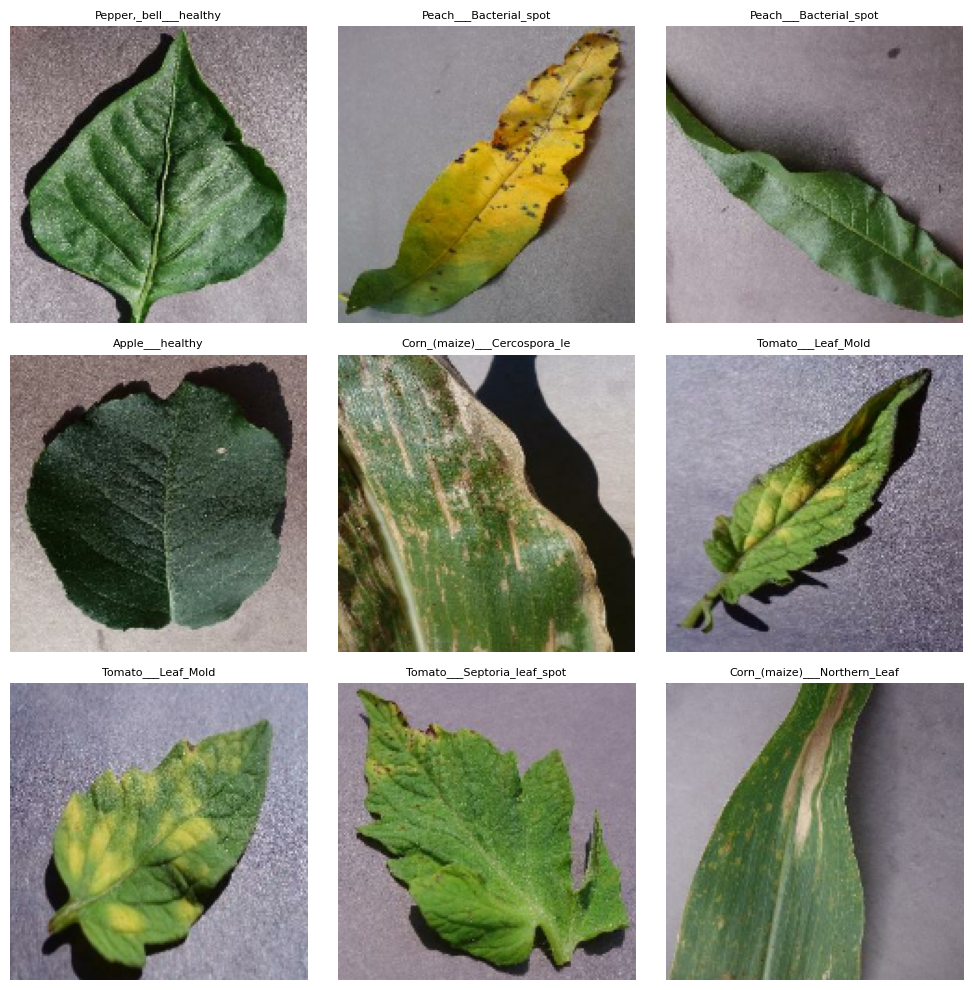

In [ ]:
plt.figure(figsize=(10,10))
for imgs, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]][:28], fontsize=8); plt.axis("off")
plt.tight_layout(); plt.savefig("samples.png", dpi=150); plt.show()

## 2. Model A: CNN from scratch

In [ ]:
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
])

def conv_block(x, f):
    x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    return layers.MaxPooling2D()(x)

inp = layers.Input(shape=IMG + (3,))
x = augment(inp)
x = layers.Rescaling(1./255)(x)
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
out = layers.Dense(num_classes, activation="softmax")(x)
model_a = models.Model(inp, out, name="cnn_scratch")

model_a.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_a.summary()

Model: "cnn_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465,894 (1.78 MB)

 Trainable params: 464,934 (1.77 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
cb = lambda: [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_loss"),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2, verbose=1),
]
hist_a = model_a.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=cb())

Epoch 1/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 182s 145ms/step - accuracy: 0.6272 - loss: 1.2741 - val_accuracy: 0.4759 - val_loss: 2.4245 - learning_rate: 0.0010
Epoch 2/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 124s 104ms/step - accuracy: 0.8234 - loss: 0.5651 - val_accuracy: 0.7108 - val_loss: 1.0815 - learning_rate: 0.0010
Epoch 3/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 122s 102ms/step - accuracy: 0.8828 - loss: 0.3623 - val_accuracy: 0.5049 - val_loss: 2.7898 - learning_rate: 0.0010
Epoch 4/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 118s 99ms/step - accuracy: 0.9107 - loss: 0.2741 - val_accuracy: 0.7966 - val_loss: 0.8241 - learning_rate: 0.0010
Epoch 5/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 117s 99ms/step - accuracy: 0.9277 - loss: 0.2229 - val_accuracy: 0.8869 - val_loss: 0.3938 - learning_rate: 0.0010
Epoch 6/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 121s 102ms/step - accuracy: 0.9381 - loss: 0.1957 - val_accuracy: 0.9453 - val_loss: 0.1812 - learning_rate: 0.0010
Epoch 7/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 119s 100ms/s

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 3. Model B: MobileNetV2 transfer learning

In [ ]:
base = tf.keras.applications.MobileNetV2(input_shape=IMG+(3,), include_top=False, weights="imagenet")
base.trainable = False

inp = layers.Input(shape=IMG + (3,))
x = augment(inp)
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(num_classes, activation="softmax")(x)
model_b = models.Model(inp, out, name="mobilenetv2_tl")

model_b.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_b = model_b.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb())

# Optional fine-tuning of the top layers
base.trainable = True
for l in base.layers[:-30]: l.trainable = False
model_b.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_b2 = model_b.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=cb())

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 92s 73ms/step - accuracy: 0.8181 - loss: 0.6283 - val_accuracy: 0.8949 - val_loss: 0.3385 - learning_rate: 0.0010
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 84s 71ms/step - accuracy: 0.8956 - loss: 0.3271 - val_accuracy: 0.9130 - val_loss: 0.2719 - learning_rate: 0.0010
Epoch 3/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 85s 71ms/step - accuracy: 0.9043 - loss: 0.2959 - val_accuracy: 0.9214 - val_loss: 0.2478 - learning_rate: 0.0010
Epoch 4/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 85s 72ms/step - accuracy: 0.9114 - loss: 0.2744 - val_accuracy: 0.9237 - val_loss: 0.2305 - learning_rate: 0.0010
Epoch 5/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 85s 72ms/step - accuracy: 0.9137 - loss: 0.2661 - val_accuracy: 0.9222 - val_loss: 0.2401 - learning_rate: 0.0010
Epoch 6/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9133 - loss: 0.2657
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
1188/1

## 4. Training curves

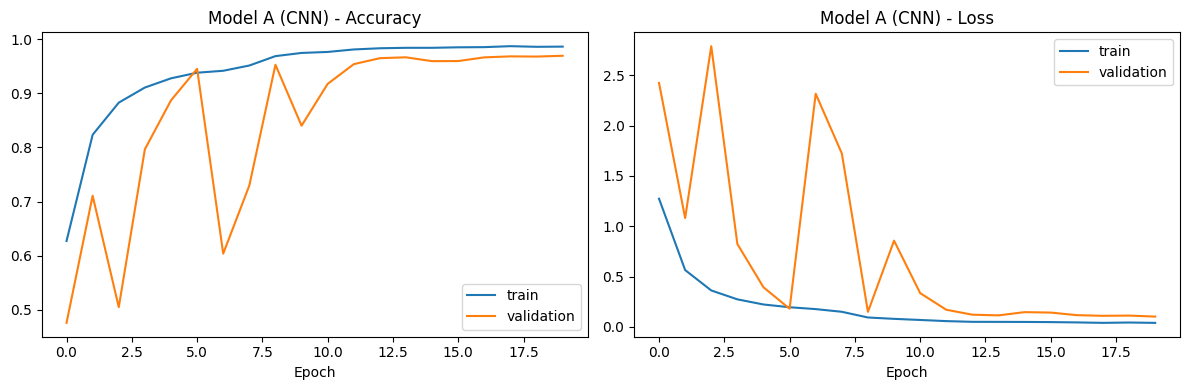

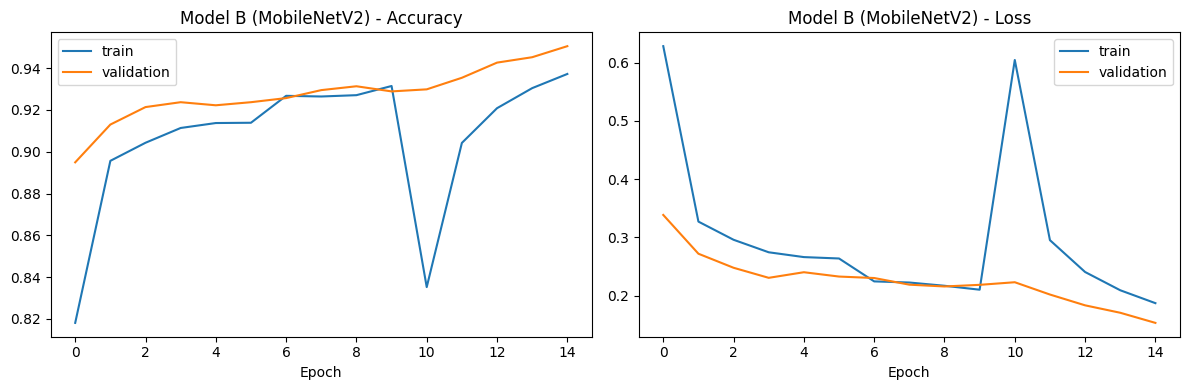

In [ ]:
def plot_hist(hists, title, fname):
    acc = sum([h.history["accuracy"] for h in hists], [])
    val = sum([h.history["val_accuracy"] for h in hists], [])
    loss = sum([h.history["loss"] for h in hists], [])
    vloss = sum([h.history["val_loss"] for h in hists], [])
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    ax[0].plot(acc, label="train"); ax[0].plot(val, label="validation")
    ax[0].set_title(title+" - Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(loss, label="train"); ax[1].plot(vloss, label="validation")
    ax[1].set_title(title+" - Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

plot_hist([hist_a], "Model A (CNN)", "curves_a.png")
plot_hist([hist_b, hist_b2], "Model B (MobileNetV2)", "curves_b.png")

## 5. Evaluation on the test set

In [ ]:
def evaluate(model, name):
    y_true, y_pred = [], []
    for x, y in test_ds:
        y_true += list(y.numpy())
        y_pred += list(np.argmax(model.predict(x, verbose=0), axis=1))
    acc = np.mean(np.array(y_true) == np.array(y_pred))
    print(f"\n{name} test accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    return np.array(y_true), np.array(y_pred), acc

yt_a, yp_a, acc_a = evaluate(model_a, "Model A (CNN)")
yt_b, yp_b, acc_b = evaluate(model_b, "Model B (MobileNetV2)")

print("\n| Model | Test Accuracy |\n|---|---|")
print(f"| CNN from scratch | {acc_a:.4f} |\n| MobileNetV2 (TL) | {acc_b:.4f} |")


Model A (CNN) test accuracy: 0.9700
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      1.000     0.978     0.989        92
                                 Apple___Black_rot      0.924     1.000     0.960        97
                          Apple___Cedar_apple_rust      1.000     1.000     1.000        41
                                   Apple___healthy      0.953     0.984     0.969       250
                               Blueberry___healthy      0.995     1.000     0.998       215
          Cherry_(including_sour)___Powdery_mildew      1.000     0.962     0.981       186
                 Cherry_(including_sour)___healthy      0.971     1.000     0.985       132
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.835     0.989     0.905        87
                       Corn_(maize)___Common_rust_      0.994     1.000     0.997       162
               Corn_(maize)___Northern_Lea

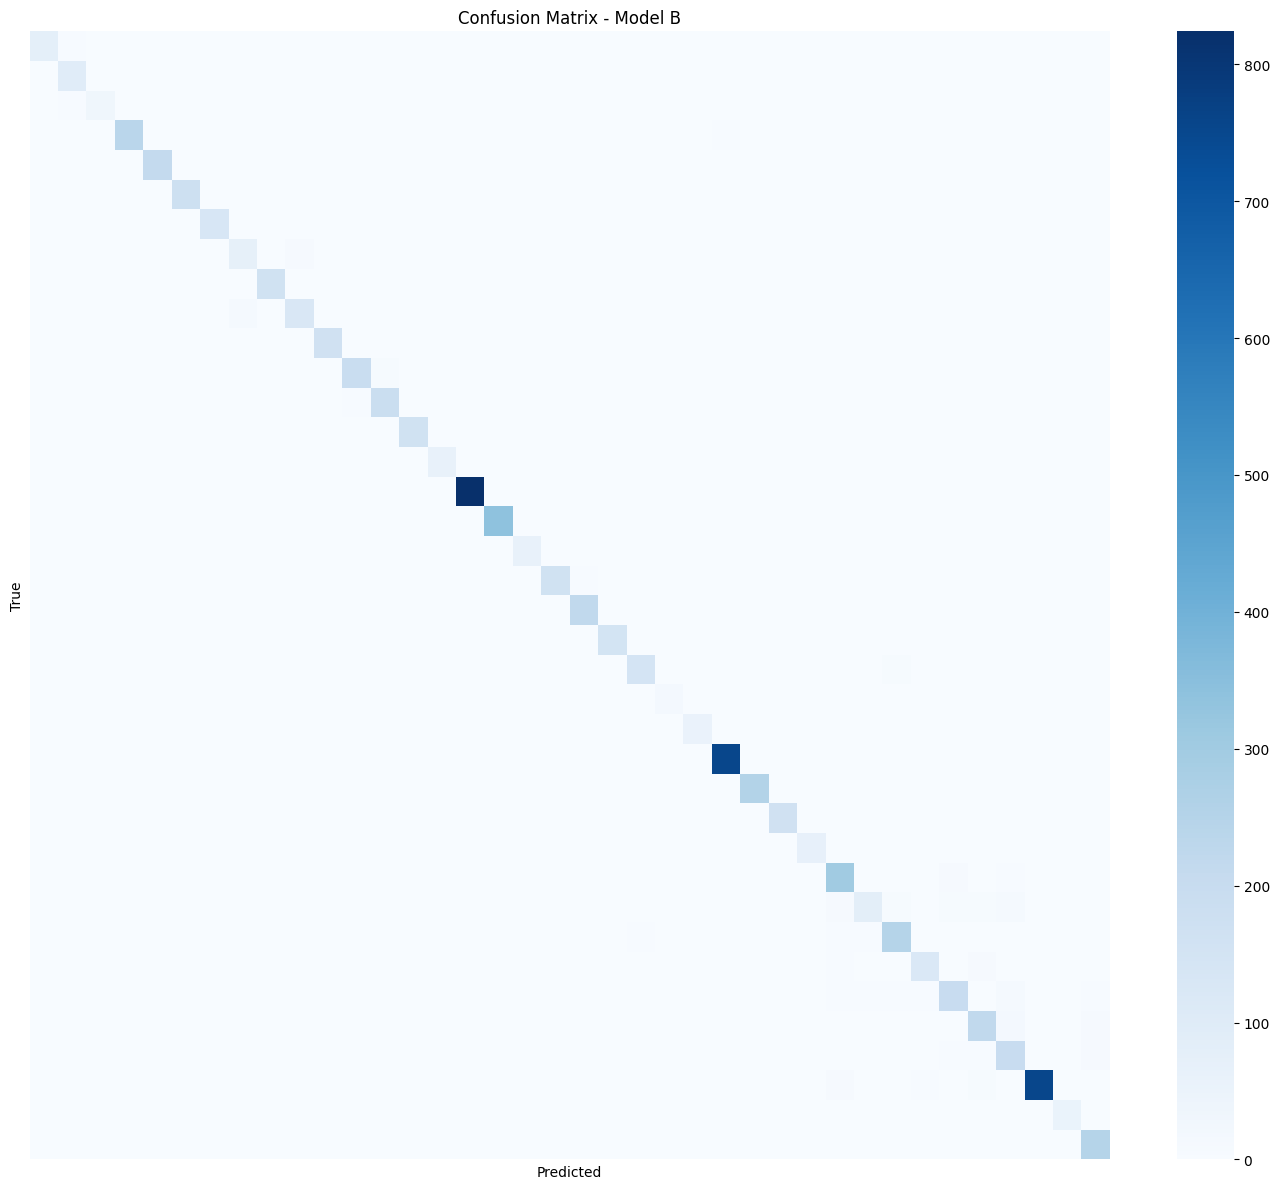

In [ ]:
cm = confusion_matrix(yt_b, yp_b)
plt.figure(figsize=(14,12))
sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title("Confusion Matrix - Model B"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.savefig("confusion_b.png", dpi=150); plt.show()

## 6. Sample predictions

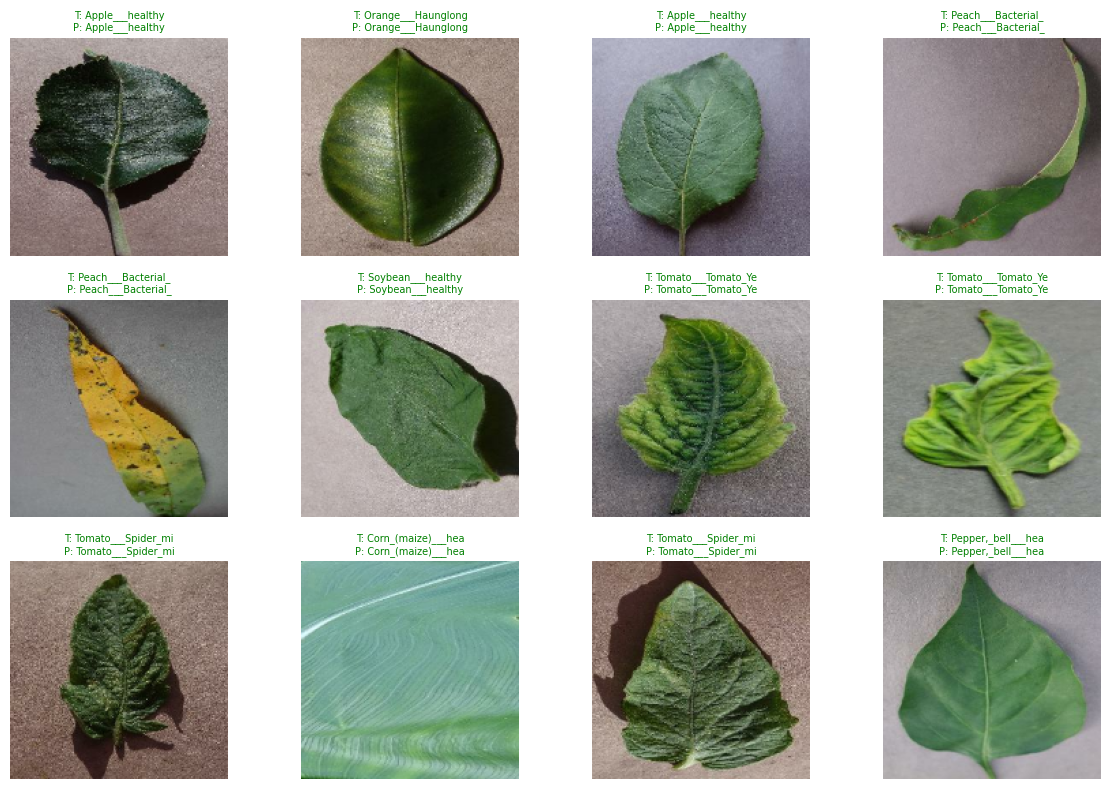

In [ ]:
plt.figure(figsize=(12,8))
for imgs, labels in test_ds.take(1):
    preds = np.argmax(model_b.predict(imgs, verbose=0), axis=1)
    for i in range(12):
        plt.subplot(3,4,i+1)
        plt.imshow(imgs[i].numpy().astype("uint8")); plt.axis("off")
        ok = preds[i] == labels[i].numpy()
        plt.title(f"T: {class_names[labels[i]][:18]}\nP: {class_names[preds[i]][:18]}",
                  fontsize=7, color="green" if ok else "red")
plt.tight_layout(); plt.savefig("predictions.png", dpi=150); plt.show()

## 7. Grad-CAM (where does the model look?)

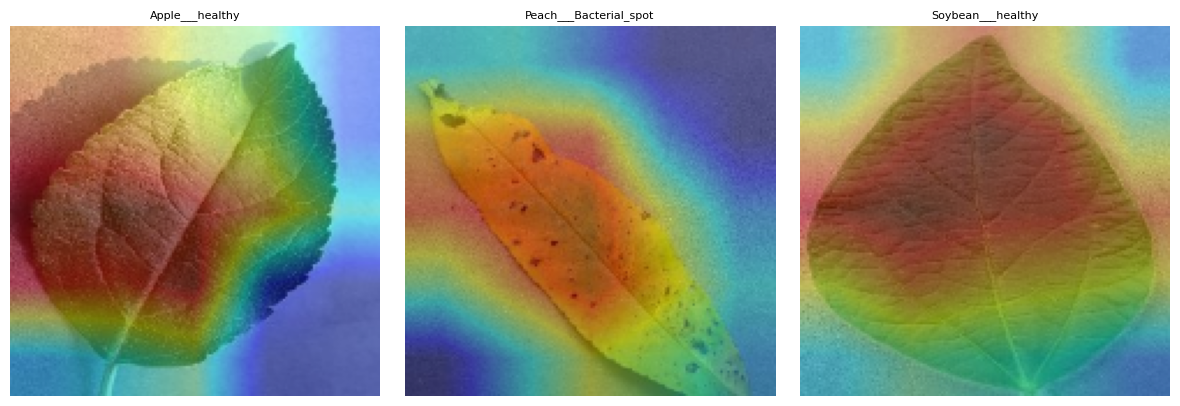

In [16]:
import cv2
def gradcam(model, img_array, last_conv="Conv_1"):
    base_m = model.get_layer("mobilenetv2_1.00_160")
    conv_out = base_m.get_layer(last_conv).output
    sub = tf.keras.Model(base_m.input, [conv_out, base_m.output])
    x = tf.keras.applications.mobilenet_v2.preprocess_input(img_array[None].copy())
    with tf.GradientTape() as tape:
        c, f = sub(x)
        tape.watch(c)
        p = model.layers[-1](tf.reduce_mean(f, axis=(1,2)))
        idx = tf.argmax(p[0]); loss = p[:, idx]
    g = tape.gradient(loss, c)
    w = tf.reduce_mean(g, axis=(1,2))
    cam = tf.reduce_sum(c * w[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam).numpy(); cam /= (cam.max() + 1e-8)
    return cam, int(idx)

plt.figure(figsize=(12,4))
for imgs, labels in test_ds.take(1):
    for i in range(3):
        img = imgs[i].numpy()
        try:
            cam, idx = gradcam(model_b, img)
            hm = cv2.applyColorMap(np.uint8(255*cv2.resize(cam, IMG)), cv2.COLORMAP_JET)[..., ::-1]
            over = np.uint8(0.6*img + 0.4*hm)
            plt.subplot(1,3,i+1); plt.imshow(over); plt.axis("off"); plt.title(class_names[idx][:25], fontsize=8)
        except Exception as e:
            print("Grad-CAM skipped (layer names differ):", e); break
plt.tight_layout(); plt.savefig("gradcam.png", dpi=150); plt.show()

In [ ]:
model_a.save("model_a_cnn.keras"); model_b.save("model_b_mobilenetv2.keras")

In [ ]:
from google.colab import drive
import shutil, glob, os
drive.mount('/content/drive')

dst = "/content/drive/MyDrive/plant_disease_project"
os.makedirs(dst, exist_ok=True)
for f in glob.glob("*.png") + glob.glob("*.keras"):
    shutil.copy(f, dst)
print("Kopyalandı:", os.listdir(dst))

Mounted at /content/drive
Kopyalandı: ['curves_b.png', 'samples.png', 'gradcam.png', 'curves_a.png', 'confusion_b.png', 'predictions.png', 'model_b_mobilenetv2.keras', 'model_a_cnn.keras']


In [ ]:
import zipfile, glob
from google.colab import files
with zipfile.ZipFile("grafikler.zip", "w") as z:
    for f in glob.glob("*.png"):
        z.write(f)
files.download("grafikler.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>